# A single skewer: HI (peak+blend) vs Si III, same halo, same skewer

This notebook extracts a **single skewer** at a configurable impact parameter
around a halo of mass $\sim 10^{10}\,M_\odot$ in TNG50-2 (snap 25,
$z\sim3$), and runs fake_spectra **twice** on exactly that same skewer:

1. **HI (Ly$\alpha$)**, using the HCD fork with `filter_mode="HCD_only"` and
   `hcd_algorithm="peaks+blend"` -- the peak+blend decomposition implemented
   in `fake_spectra_fork/fake_spectra/spectra.py` (see `HCD_ALGORITHMS` and
   `Spectra._hcd_peak_mask` / `Spectra._blend_test` in that file).
2. **Si III (1206.5 Å)**, changing *only* the absorbing element/line --
   same halo, same skewer, same snapshot. If possible, the cell reuses
   exactly the same gas cells that peak+blend selected for HI and computes
   the Si III transmitted flux from those cells only; if that is not
   possible (the corresponding cell explains why), it falls back to the
   full Si III sightline (`filter_mode="None"`, stock fake_spectra).
3. The two absorption profiles (HI and Si III) are then plotted together, on
   the same velocity axis, centred on the halo rest frame.

Only this notebook is touched here -- `spectra.py` itself is not modified.

## 1. Setup

In [18]:
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

# --- project modules ------------------------------------------------------
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
sys.path.insert(0, str(PROJ_ROOT / "tools"))
import utils as u            # tools/utils.py  -- SimulationContext, HaloFinder, SpectrumEngine
import radii_skewers as rs   # tools/radii_skewers.py (not strictly needed here, kept for parity)

# --- the HCD fork of fake_spectra ------------------------------------------
import inspect
import fake_spectra.spectra as spectra

# Fail loudly (not three cells later with a cryptic AttributeError) if the
# stock upstream fake_spectra is installed instead of the HCD fork.
assert 'filter_mode' in inspect.signature(spectra.Spectra.__init__).parameters, (
    "The installed fake_spectra.spectra.Spectra has no 'filter_mode' argument -- "
    "this is stock upstream fake_spectra, not the HCD fork "
    "(fake_spectra_fork/fake_spectra/spectra.py). Install the fork first:\n"
    '  pip install "git+https://github.com/VictorRoberto132/fake_spectra@v2.2.4-hcd1"')
print("fake_spectra (fork) loaded from:", spectra.__file__)
print("HCD algorithms available       :", spectra.HCD_ALGORITHMS)
print("HCD selection cut, log N_HI    :", spectra.HCD_SELECTION_LOGNHI)

# --- simulation -------------------------------------------------------------
BASE_PATH = "/home/STORAGE/TNG50-2"
SIM_NAME  = "TNG50-2"
SIM_TYPE  = "TNG"
SNAP_NUM  = 25            # snap 25 -> z ~ 3.0 in TNG50

ctx = u.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
hf  = u.HaloFinder(ctx)

# Header constants needed to convert Group_M_Crit200 (1e10 Msun/h) to
# physical Msun, and to report the redshift of the snapshot.
with h5py.File(ctx.get_group_file(0), 'r') as f:
    hubble_h = float(f['Header'].attrs['HubbleParam'])
    redshift = float(f['Header'].attrs['Redshift'])
print(f"{SIM_NAME} snap {SNAP_NUM}: z = {redshift:.3f}, h = {hubble_h}")

fake_spectra (fork) loaded from: /home/vroberto/fake_spectra_fork/fake_spectra/spectra.py
HCD algorithms available       : ('peaks', 'peaks+blend', 'region_growing')
HCD selection cut, log N_HI    : 17.2
TNG50-2 snap 25: z = 3.008, h = 0.6774


## 2. Configuration: target halo mass and impact parameter

Every knob that controls **which** skewer gets extracted lives in this one
cell, so this is the place to look/change things:

* `TARGET_LOG_MASS`, `MASS_WINDOW_DEX` -- the halo mass window,
  $\log_{10}(M/M_\odot) \in [\text{target} \pm \Delta]$. `Group_M_Crit200` in
  the catalogue is stored in $10^{10}\,M_\odot/h$; it gets converted to
  physical $M_\odot$ with the snapshot's own `h` before comparing.
* **`IMPACT_R_MULTIPLIER`** -- the impact parameter $b$, in units of
  $R_{200}$. **This is the parameter that answers "can I set the impact
  parameter?" -- yes, right here.** `0.0` sends the sightline exactly through
  the halo centre; any positive value offsets it perpendicular to the
  line-of-sight axis by that many $R_{200}$. Default here is `0.5`, i.e. a
  skewer passing at half an $R_{200}$ from the centre -- change it to
  whatever value you need.
* `IMPACT_DIRECTION` -- which of the four cardinal directions perpendicular
  to the sightline the offset points along. Uses the same
  `"Right"/"Left"/"Top"/"Bottom"` convention as
  `tools/radii_skewers.py`'s `SkewerGeometry.generate_skewers`, so this
  notebook's geometry matches the production pipeline exactly.
* `MAX_CANDIDATES` -- how many halos in the mass window get tried (see
  Section 3) before giving up. A larger impact parameter finds fewer
  genuine HCD sightlines per halo, so it may need to look at more halos.
* `RES_KMS` -- pixel width of the extracted spectrum, km/s. Matches the
  production pipeline's default (10 km/s).

In [19]:
# --- halo mass window -------------------------------------------------------
TARGET_LOG_MASS = 10.0     # log10(M_sun), physical -- the target halo mass (~10^10 Msun by default)
MASS_WINDOW_DEX = 0.15     # search 10**(10-0.15) .. 10**(10+0.15) Msun
MAX_CANDIDATES  = 200      # at most this many halos in the window are tried

# --- impact parameter --------------------------------------------------------
IMPACT_R_MULTIPLIER = 0.5   # b, in units of R_200. 0.0 = straight through the centre.
IMPACT_DIRECTION    = "Right"   # one of "Right", "Left", "Top", "Bottom"

# --- spectral pixel width ----------------------------------------------------
RES_KMS = 10.0   # km/s

print(f"target halo mass : 10^{TARGET_LOG_MASS} Msun +/- {MASS_WINDOW_DEX} dex")
print(f"impact parameter : b = {IMPACT_R_MULTIPLIER} R_200, direction = {IMPACT_DIRECTION}")

target halo mass : 10^10.0 Msun +/- 0.15 dex
impact parameter : b = 0.5 R_200, direction = Right


## 3. Candidate halos

Scan the FoF group catalogue for halos whose `Group_M_Crit200` falls in the
configured mass window, closest to `TARGET_LOG_MASS` first, so the search in
Section 4 always tries the most on-target halos first and the whole notebook
is reproducible (same candidate order every run, for a fixed configuration).

In [20]:
def candidate_halo_ids(base_path, snap_num, log_lo, log_hi, hubble_h, target_log_mass):
    '''Global halo ids with Group_M_Crit200 in the given physical M_sun window,
    closest to `target_log_mass` first. Group_M_Crit200 is 1e10 M_sun/h.'''
    group_dir = Path(base_path) / f"groups_{snap_num:03d}"
    with h5py.File(group_dir / f"fof_subhalo_tab_{snap_num:03d}.0.hdf5", 'r') as f:
        n_files = int(f['Header'].attrs['NumFiles'])
    lo_code = (10 ** log_lo) * hubble_h / 1e10
    hi_code = (10 ** log_hi) * hubble_h / 1e10
    ids, masses, offset = [], [], 0
    for i in range(n_files):
        fp = group_dir / f"fof_subhalo_tab_{snap_num:03d}.{i}.hdf5"
        if not fp.exists():
            continue
        with h5py.File(fp, 'r') as f:
            if 'Group' not in f or 'Group_M_Crit200' not in f['Group']:
                continue
            m = f['Group']['Group_M_Crit200'][:]
            in_win = np.flatnonzero((m >= lo_code) & (m < hi_code))
            ids.extend((offset + in_win).tolist())
            masses.extend(m[in_win].tolist())
            offset += len(m)
    if not ids:
        return []
    log_m_phys = np.log10(np.array(masses) * 1e10 / hubble_h)
    order = np.argsort(np.abs(log_m_phys - target_log_mass))
    return [ids[i] for i in order[:MAX_CANDIDATES]]


cand_ids = candidate_halo_ids(BASE_PATH, SNAP_NUM,
                               TARGET_LOG_MASS - MASS_WINDOW_DEX,
                               TARGET_LOG_MASS + MASS_WINDOW_DEX,
                               hubble_h, TARGET_LOG_MASS)
print(f"{len(cand_ids)} candidate halo(s) with log10(M/Msun) in "
      f"[{TARGET_LOG_MASS - MASS_WINDOW_DEX}, {TARGET_LOG_MASS + MASS_WINDOW_DEX}]")

200 candidate halo(s) with log10(M/Msun) in [9.85, 10.15]


## 4. HI, peak+blend

For each candidate halo (mass closest to target first) and each of the three
box axes, build the sightline at the configured impact parameter and run the
HCD fork with `filter_mode="HCD_only"`, `hcd_algorithm="peaks+blend"`. Stop
at the first sightline the decomposition flags as an HCD
($\log N_{\rm HI} \geq 17.2$, `spectra.HCD_SELECTION_LOGNHI`) -- a smaller
impact parameter finds one almost immediately, a larger one may need to
look through more halos/axes, since fewer sightlines that far out cross
self-shielded gas at all.

In [21]:
IMPACT_DIRECTIONS = {   # (component along the 1st, 2nd perpendicular axis)
    "Right":  (1.0, 0.0),
    "Left":   (-1.0, 0.0),
    "Top":    (0.0, 1.0),
    "Bottom": (0.0, -1.0),
}


def offset_vector(axis_0indexed, r_multiplier, halo_r200, direction):
    '''Perpendicular offset (code length units) of a sightline along
    `axis_0indexed`, at impact parameter r_multiplier * halo_r200, pointing
    along one of the four cardinal directions perpendicular to that axis.
    Same convention as tools/radii_skewers.py's SkewerGeometry, so
    r_multiplier = 0 always passes exactly through the halo centre.
    '''
    o1, o2 = IMPACT_DIRECTIONS[direction]
    impact = r_multiplier * halo_r200
    vec = np.zeros(3)
    free = [k for k in range(3) if k != axis_0indexed]   # the two axes perpendicular to the LOS
    vec[free[0]] = o1 * impact
    vec[free[1]] = o2 * impact
    return vec


halo, eng, axis_array, cofm_array = None, None, None, None
wave = v_grid = chi = flux_H = colden_H = lam_rest = None
is_hcd = False
log_n_hi = 0.0

for hid in cand_ids:
    hcand = hf.get_halo_properties(hid)
    base_cm = np.mod(hcand['cm'], hcand['box_size'])   # halo centre, wrapped into the box
    log_m = np.log10(hcand['mass'] * 1e10 / hubble_h)
    found_axis = None
    for ax in range(3):   # try X, Y, Z before moving on to the next halo
        offset = offset_vector(ax, IMPACT_R_MULTIPLIER, hcand['r200'], IMPACT_DIRECTION)
        cofm = np.mod(base_cm + offset, hcand['box_size'])   # periodic boundary
        axis_try = np.array([ax + 1], dtype=np.int32)        # fake_spectra axes are 1-indexed
        cofm_try = np.array([cofm], dtype=np.float64)

        eng_try = u.SpectrumEngine(ctx, hcand, res=RES_KMS,
                                    spectra_kwargs=dict(hcd_algorithm="peaks+blend"))
        eng_try.generate_skewer_batch(axis_try, cofm_try, filter_mode="HCD_only", with_temp=False)
        (wave_try, v_grid_try, chi_try, flux_try, colden_try,
         _temp_try, lam_rest_try, is_hcd_try) = eng_try.get_centered_spectrum(0)
        tot = eng_try.get_total_col_den(0)
        lognhi_try = np.log10(tot) if tot > 0 else 0.0
        print(f"halo {hid:>7} (log M={log_m:.2f}) axis {'XYZ'[ax]}: "
              f"log N_HI = {lognhi_try:5.2f}  is_hcd = {is_hcd_try}")
        if is_hcd_try:
            found_axis = ax
            (halo, eng, axis_array, cofm_array,
             wave, v_grid, chi, flux_H, colden_H, lam_rest, is_hcd, log_n_hi) = (
                hcand, eng_try, axis_try, cofm_try,
                wave_try, v_grid_try, chi_try, flux_try, colden_try,
                lam_rest_try, is_hcd_try, lognhi_try)
            break
    if found_axis is not None:
        break

if halo is None:
    raise RuntimeError(
        "No halo in the mass window produced an HCD sightline at this impact "
        "parameter; widen MASS_WINDOW_DEX / MAX_CANDIDATES, or reduce "
        "IMPACT_R_MULTIPLIER, in Section 2 above and re-run.")

axis_letter = "XYZ"[int(axis_array[0]) - 1]
print(f"\nUsing halo {halo['id']}: log10(M) = {np.log10(halo['mass']*1e10/hubble_h):.2f}, "
      f"R200 = {halo['r200']:.2f} (code units), axis = {axis_letter}, "
      f"impact parameter b = {IMPACT_R_MULTIPLIER} R_200 ({IMPACT_DIRECTION})")
print(f"Sightline: log N_HI = {log_n_hi:.2f} (peak+blend), is_hcd = {is_hcd}")

halo   14174 (log M=10.00) axis X: log N_HI =  0.00  is_hcd = False
halo   14174 (log M=10.00) axis Y: log N_HI =  0.00  is_hcd = False
halo   14174 (log M=10.00) axis Z: log N_HI =  0.00  is_hcd = False
halo   12533 (log M=10.00) axis X: log N_HI =  0.00  is_hcd = False
halo   12533 (log M=10.00) axis Y: log N_HI =  0.00  is_hcd = False
halo   12533 (log M=10.00) axis Z: log N_HI = 18.93  is_hcd = True

Using halo 12533: log10(M) = 10.00, R200 = 45.01 (code units), axis = Z, impact parameter b = 0.5 R_200 (Right)
Sightline: log N_HI = 18.93 (peak+blend), is_hcd = True


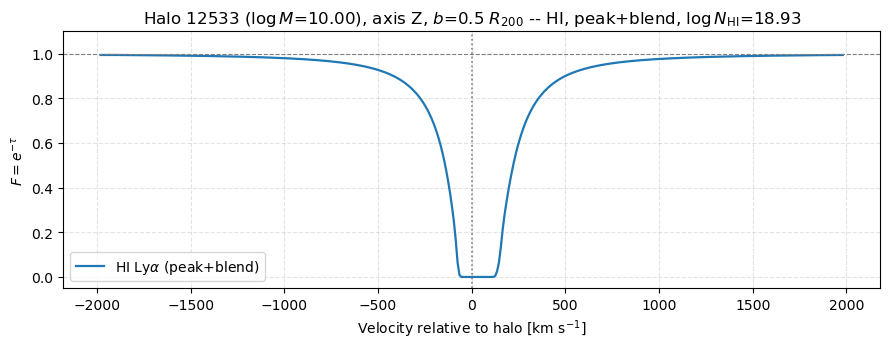

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(v_grid, flux_H, color="tab:blue", lw=1.6, label=r"HI Ly$\alpha$ (peak+blend)")
ax.axhline(1.0, color="gray", ls="--", lw=0.8)
ax.axvline(0.0, color="gray", ls=":", lw=1.2)
ax.set_xlabel(r"Velocity relative to halo [km s$^{-1}$]")
ax.set_ylabel(r"$F = e^{-\tau}$")
ax.set_ylim(-0.05, 1.1)
ax.set_title(rf"Halo {halo['id']} ($\log M$={np.log10(halo['mass']*1e10/hubble_h):.2f}), "
             rf"axis {axis_letter}, $b$={IMPACT_R_MULTIPLIER} $R_{{200}}$ -- "
             rf"HI, peak+blend, $\log N_{{\rm HI}}$={log_n_hi:.2f}")
ax.grid(True, ls="--", alpha=0.35)
ax.legend()
plt.tight_layout(); plt.show()

## 5. Si III, same skewer, same halo

Only the absorbing species/line changes: from HI Ly$\alpha$ (1215.67 Å) to
**Si III 1206.500 Å** (`atom.dat`, line `SiIII  1206.500`). `halo`,
`axis_array` and `cofm_array` are the exact same objects as in the previous
section -- same impact parameter, same sightline.

**Why "reuse the peak+blend cells" is not simply
`filter_mode="HCD_only"` with `elem="Si"`:** inside the fork, the cut that
decides whether a structure is an "HCD" (`HCD_SELECTION_THRESH = 10**17.2`,
see `spectra.py`) is compared against the column density **of whichever
element was requested** (`elem_den`, computed by
`_hcd_peak_mask`/`_cell_column`). That is correct for HI, but the Si III
column never gets anywhere near $10^{17.2}\,{\rm cm^{-2}}$ -- so naively
asking for this would not "reuse" anything, it would just produce an
always-empty mask (flux = 1 everywhere), which would look like it worked but
would be physically wrong.

**What the cell below actually does:** it reuses the *particle indices* that
peak+blend already accepted for HI (stored in the fork's own performance
caches, `Spectra._hcd_mask_cache` / `Spectra._particle_cache` -- see the
"PERF caches" comments in `spectra.py`) and applies those SAME indices to a
fresh read of the Si III density of those SAME gas cells. This is valid
because a cell's position and smoothing length do not depend on which ion is
being interpolated, and both reads use exactly the same skewer (`axis`,
`cofm`). A sanity check (positions matching cell-for-cell) runs before the
result is accepted.

This reaches into "private" attributes of the fork (not a public/documented
API) -- so the function below is only a best effort: if any check fails (for
example, HI selected no cells at all on this sightline), it automatically
falls back to the **full** Si III sightline (`filter_mode="None"`, stock
fake_spectra), exactly as requested.

In [23]:
SI_ELEM, SI_ION, SI_LINE = "Si", 3, 1206   # SiIII, 1206.500 A (fake_spectra keys lines by int(lambda))


def restricted_siIII_tau(eng, axis_array, cofm_array):
    '''Best-effort: Si III optical depth using ONLY the gas cells the HI
    peak+blend decomposition already accepted for this skewer.

    Returns (tau_si, True) on success, or (None, False) if the assumption
    documented in the markdown cell above does not check out -- the caller
    then falls back to the full, unfiltered Si III sightline.
    '''
    ss_H = eng.ss
    key_H = (0, "H", 1)
    if key_H not in ss_H._hcd_mask_cache or key_H not in ss_H._particle_cache:
        return None, False
    ind_final = ss_H._hcd_mask_cache[key_H][0]
    if ind_final is None or len(ind_final) == 0:
        return None, False   # peak+blend accepted no cells on this LOS -- nothing to reuse
    pos_H = ss_H._particle_cache[key_H]['data'][0]

    # A second Spectra object for the SAME skewer. filter_mode="HCD_only" is
    # passed only to force the fork to populate its per-(elem, ion) PERF
    # cache with the concatenated Si III particle arrays; its own (physically
    # meaningless, see markdown above) Si-based peaks+blend verdict is
    # computed but discarded.
    ss_Si = eng._build_spectra(axis_array, cofm_array, filter_mode="HCD_only")
    _ = ss_Si.get_tau(SI_ELEM, SI_ION, SI_LINE)

    key_Si = (0, SI_ELEM, SI_ION)
    if key_Si not in ss_Si._particle_cache:
        return None, False
    pos_Si, vel_Si, elem_den_Si, temp_Si, hh_Si, amumass_Si, den_Si = \
        ss_Si._particle_cache[key_Si]['data']

    if len(pos_Si) != len(pos_H) or int(np.max(ind_final)) >= len(pos_Si):
        return None, False
    n_check = min(50, len(ind_final))
    if not np.allclose(pos_Si[ind_final][:n_check], pos_H[ind_final][:n_check],
                        rtol=0, atol=1e-4):
        return None, False   # the two reads did not line up cell-for-cell -- bail out

    line_Si = ss_Si.lines[(SI_ELEM, SI_ION)][SI_LINE]
    tau_si = ss_Si._do_interpolation_work(
        pos_Si[ind_final], vel_Si[ind_final], elem_den_Si[ind_final],
        temp_Si[ind_final], hh_Si[ind_final], amumass_Si, line_Si, True)[0]
    return tau_si, True


tau_si_masked, used_peak_blend_cells = restricted_siIII_tau(eng, axis_array, cofm_array)

if used_peak_blend_cells:
    tau_si = tau_si_masked
    si_method = "peak+blend cells only (reused from the HI decomposition above)"
else:
    ss_Si_full = eng._build_spectra(axis_array, cofm_array, filter_mode="None")
    tau_si = ss_Si_full.get_tau(SI_ELEM, SI_ION, SI_LINE)[0]
    si_method = "full sightline, stock fake_spectra (fallback)"

print("Si III method used:", si_method)

# Centre on the halo rest frame exactly like the HI spectrum above, so both
# share one velocity axis (same skewer -> same nbins, dvbin, vmax, velfac).
v_axis = np.arange(eng.ss.nbins) * (eng.ss.vmax / eng.ss.nbins)
v_sys = eng._systemic_velocity(int(axis_array[0]))
flux_Si_raw = np.exp(-tau_si)
flux_Si = u.SpectrumEngine._center(flux_Si_raw, v_axis, v_grid, v_sys, eng.ss.vmax)

print(f"Si III: max optical depth = {np.max(tau_si):.4g}, "
      f"min flux = {np.min(flux_Si):.4f}")

Si III method used: peak+blend cells only (reused from the HI decomposition above)
Si III: max optical depth = 1.404, min flux = 0.2577


## 6. Both absorption profiles together

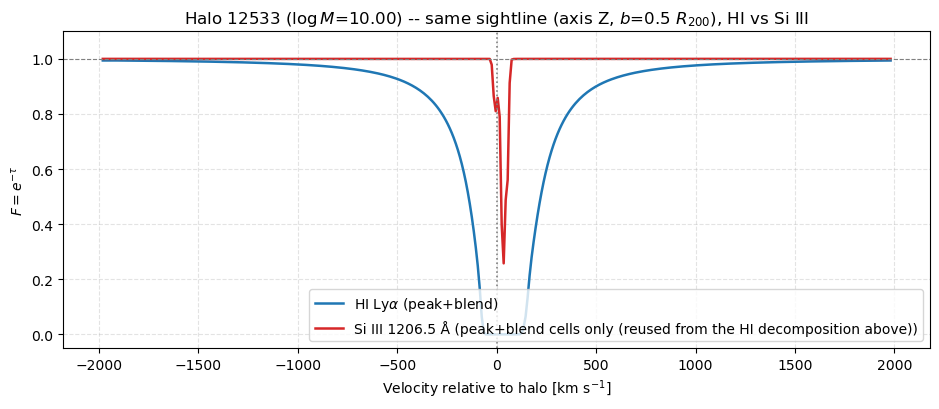

In [24]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(v_grid, flux_H, color="tab:blue", lw=1.8, label=r"HI Ly$\alpha$ (peak+blend)")
ax.plot(v_grid, flux_Si, color="tab:red", lw=1.8,
        label=f"Si III 1206.5 Å ({si_method})")
ax.axhline(1.0, color="gray", ls="--", lw=0.8)
ax.axvline(0.0, color="gray", ls=":", lw=1.2)
ax.set_xlabel(r"Velocity relative to halo [km s$^{-1}$]")
ax.set_ylabel(r"$F = e^{-\tau}$")
ax.set_ylim(-0.05, 1.1)
ax.set_title(rf"Halo {halo['id']} ($\log M$={np.log10(halo['mass']*1e10/hubble_h):.2f}) "
             rf"-- same sightline (axis {axis_letter}, $b$={IMPACT_R_MULTIPLIER} $R_{{200}}$), "
             rf"HI vs Si III")
ax.grid(True, ls="--", alpha=0.35)
ax.legend(fontsize=10, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Observed frame: flux vs wavelength (as in a real spectrum)

The plots above are **centred**: both lines are shifted by the halo systemic
velocity (`SpectrumEngine._center`, Hubble flow + peculiar velocity) and put
on a common velocity axis, so HI and Si III land on top of each other at
$v=0$. A real spectrograph does not do that: every transition appears at its
own observed wavelength,

$$\lambda_{\rm obs} = \lambda_{\rm rest}\,(1+z_{\rm snap})\,e^{v/c},$$

where $v$ is the **raw** position along the skewer (no rest-frame centring,
box start at $z_{\rm snap}$). Since the box is periodic (period $v_{\rm max}$,
identical for every line in velocity), the one-period window shown is
$[v_{\rm sys}-v_{\rm max}/2,\, v_{\rm sys}+v_{\rm max}/2)$, so the structure
around the halo is never cut by the box seam. Si III 1206.5 Å
therefore sits $\approx 2270$ km/s ($\approx 37$ Å at $z\sim3$) blueward of
Ly$\alpha$, i.e. inside the Ly$\alpha$ forest.

* **Top:** each line alone at its own $\lambda_{\rm obs}$ (raw, uncentred flux).
* **Bottom:** what the instrument actually records, $F = F_{\rm HI}\,F_{\rm SiIII}$
  on a common wavelength grid. Outside the wavelength range covered by each
  line's box the flux is set to 1 -- in a real spectrum that region would
  contain absorption from gas outside the simulated box.

Dotted vertical lines mark where each line falls at the halo systemic
velocity.

z_snap = 3.008, box velocity length vmax = 3961.5 km/s
Ly-alpha coverage : 4845.65 - 4909.94 A (halo at 4877.82 A)
Si III   coverage : 4809.10 - 4872.91 A (halo at 4841.03 A)
box width per line: 64.3 A (Ly-alpha), 63.8 A (Si III); plotted window: 4729.1 - 4989.9 A
Si III -> Ly-alpha separation: 36.79 A = 2270 km/s


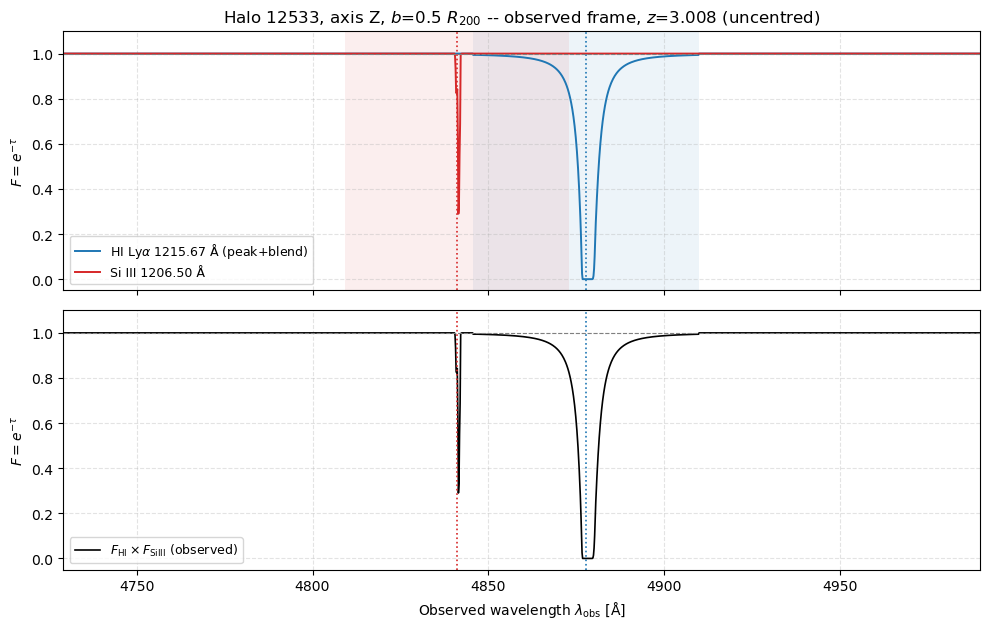

In [25]:
WINDOW_PAD_ANG = 80.0   # extra continuum (A) on each side of the region covered by the box

c_kms = u.C_LIGHT_KMS
z_snap = eng.ss.red
vmax, dvbin = eng.ss.vmax, eng.ss.vmax / eng.ss.nbins
lam_rest_H  = eng.ss.lines[("H", 1)][1215].lambda_X
lam_rest_Si = eng.ss.lines[(SI_ELEM, SI_ION)][SI_LINE].lambda_X

# Where the halo sits along the (periodic) box, in velocity.
v_sys_box = np.mod(v_sys, vmax)

# The box is periodic: tau lives on a ring of length vmax (absorption.cpp wraps
# every profile with j = z % nbins), so where the window "starts" is arbitrary.
# Starting it at v = 0 splits absorption that sits near the box edge between
# the two ends of the window. Instead, pick the one-period window centred on
# the halo, [v_sys - vmax/2, v_sys + vmax/2): same velocities, same wavelengths
# for every absorber, just no seam through the structure. Both lines get the
# SAME shift, so their relative position (Si III 2270 km/s blueward) is intact.
shift = int(np.round((v_sys_box - vmax / 2) / dvbin))
flux_H_obs  = np.roll(np.exp(-eng.tau_batch[0]), -shift)   # raw, not rest-frame centred
flux_Si_obs = np.roll(flux_Si_raw, -shift)
v_win = v_axis + shift * dvbin   # absolute velocity of each pixel (may be <0 or >vmax)

lam_obs_H  = lam_rest_H  * (1 + z_snap) * np.exp(v_win / c_kms)
lam_obs_Si = lam_rest_Si * (1 + z_snap) * np.exp(v_win / c_kms)

lam_sys_H  = lam_rest_H  * (1 + z_snap) * np.exp(v_sys_box / c_kms)
lam_sys_Si = lam_rest_Si * (1 + z_snap) * np.exp(v_sys_box / c_kms)

# Common log-uniform wavelength grid (one pixel = dvbin) covering both lines
# plus WINDOW_PAD_ANG on each side; flux = 1 outside each line's box coverage
# (the box only spans vmax, i.e. ~vmax/c * lambda_obs per line).
lam_lo = lam_obs_Si[0] - WINDOW_PAD_ANG
lam_hi = lam_obs_H[-1] + WINDOW_PAD_ANG
v_span = c_kms * np.log(lam_hi / lam_lo)
lam_common = lam_lo * np.exp(np.arange(0.0, v_span + dvbin, dvbin) / c_kms)
F_H_common  = np.interp(lam_common, lam_obs_H,  flux_H_obs,  left=1.0, right=1.0)
F_Si_common = np.interp(lam_common, lam_obs_Si, flux_Si_obs, left=1.0, right=1.0)
F_total = F_H_common * F_Si_common

print(f"z_snap = {z_snap:.3f}, box velocity length vmax = {vmax:.1f} km/s")
print(f"Ly-alpha coverage : {lam_obs_H[0]:.2f} - {lam_obs_H[-1]:.2f} A (halo at {lam_sys_H:.2f} A)")
print(f"Si III   coverage : {lam_obs_Si[0]:.2f} - {lam_obs_Si[-1]:.2f} A (halo at {lam_sys_Si:.2f} A)")
print(f"box width per line: {lam_obs_H[-1] - lam_obs_H[0]:.1f} A (Ly-alpha), "
      f"{lam_obs_Si[-1] - lam_obs_Si[0]:.1f} A (Si III); plotted window: {lam_lo:.1f} - {lam_hi:.1f} A")
print(f"Si III -> Ly-alpha separation: {lam_sys_H - lam_sys_Si:.2f} A "
      f"= {c_kms * np.log(lam_rest_H / lam_rest_Si):.0f} km/s")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
ax1.plot(lam_common, F_H_common, color="tab:blue", lw=1.4,
         label=rf"HI Ly$\alpha$ {lam_rest_H:.2f} Å (peak+blend)")
ax1.plot(lam_common, F_Si_common, color="tab:red", lw=1.4,
         label=rf"Si III {lam_rest_Si:.2f} Å")
# Shade the wavelength range actually covered by the box for each line.
ax1.axvspan(lam_obs_H[0],  lam_obs_H[-1],  color="tab:blue", alpha=0.08, lw=0)
ax1.axvspan(lam_obs_Si[0], lam_obs_Si[-1], color="tab:red",  alpha=0.08, lw=0)
ax2.plot(lam_common, F_total, color="k", lw=1.2,
         label=r"$F_{\rm HI}\times F_{\rm SiIII}$ (observed)")

for ax in (ax1, ax2):
    ax.axvline(lam_sys_H,  color="tab:blue", ls=":", lw=1.2)
    ax.axvline(lam_sys_Si, color="tab:red",  ls=":", lw=1.2)
    ax.axhline(1.0, color="gray", ls="--", lw=0.8)
    ax.set_ylim(-0.05, 1.1)
    ax.set_ylabel(r"$F = e^{-\tau}$")
    ax.grid(True, ls="--", alpha=0.35)
    ax.legend(fontsize=9, loc="lower left")

ax2.set_xlim(lam_lo, lam_hi)
ax2.set_xlabel(r"Observed wavelength $\lambda_{\rm obs}$ [Å]")
ax1.set_title(rf"Halo {halo['id']}, axis {axis_letter}, $b$={IMPACT_R_MULTIPLIER} $R_{{200}}$ "
              rf"-- observed frame, $z$={z_snap:.3f} (uncentred)")
plt.tight_layout(); plt.show()

## 8. Stock fake_spectra (no HCD modes), full sightline, $b = 0.2\,R_{200}$

Same halo, same LOS axis and same `IMPACT_DIRECTION` as above; only the impact
parameter changes to $b = 0.2\,R_{200}$. Both HI Ly$\alpha$ and Si III 1206.5 Å
are computed with `filter_mode="None"` -- the plain fake_spectra behaviour,
**all** gas cells on the skewer (forest + HCD), no peak+blend selection.

Plotted in the observed frame exactly like Section 7 (raw, not rest-frame
centred; one-period window centred on the halo so the box seam does not cut
the structure).

rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 15.6 percent done
rank = 0 | Interpolation 16.4 percent done
rank = 0 | Interpolation 17.2 percent done
rank = 0 | Interpolation 18.0 percent done
rank = 0 | Interpolatio

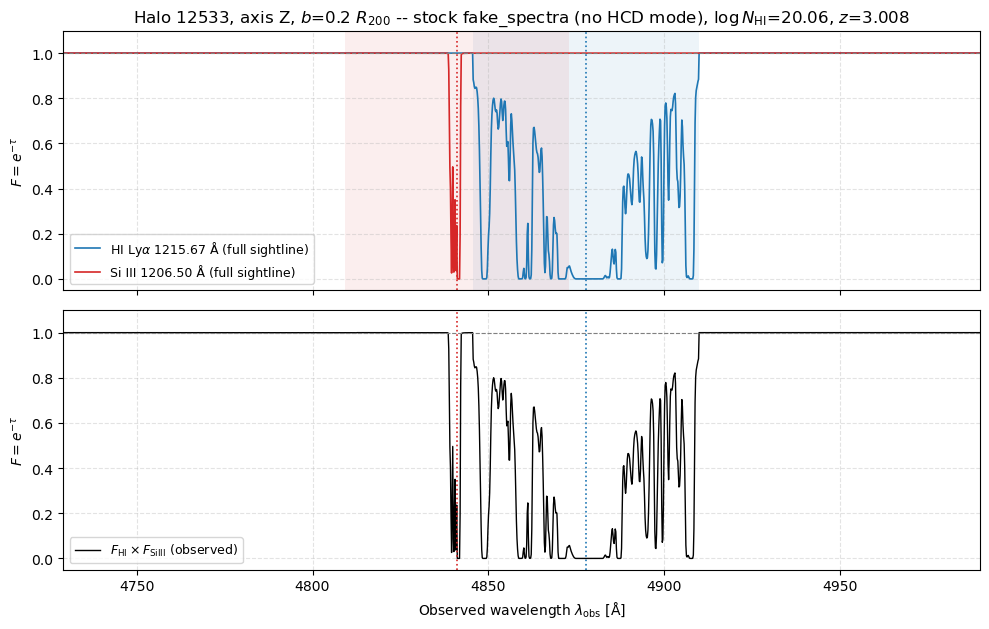

In [26]:
B_FULL = 0.2   # impact parameter for this section, in units of R_200

# Same halo, same axis, same direction -- only b changes.
ax0 = int(axis_array[0]) - 1
offset_full = offset_vector(ax0, B_FULL, halo['r200'], IMPACT_DIRECTION)
cofm_full = np.array([np.mod(np.mod(halo['cm'], halo['box_size']) + offset_full,
                             halo['box_size'])], dtype=np.float64)

# Stock behaviour: filter_mode="None", no hcd_algorithm -> every gas cell on the skewer.
eng_full = u.SpectrumEngine(ctx, halo, res=RES_KMS)
ss_full = eng_full.generate_skewer_batch(axis_array, cofm_full, filter_mode="None", with_temp=False)
tau_H_full  = eng_full.tau_batch[0]
tau_Si_full = ss_full.get_tau(SI_ELEM, SI_ION, SI_LINE)[0]
log_n_hi_full = np.log10(eng_full.get_total_col_den(0))

# Observed frame, one-period window centred on the halo (see Section 7).
vmax_f, nbins_f = ss_full.vmax, ss_full.nbins
dvbin_f = vmax_f / nbins_f
v_axis_f = np.arange(nbins_f) * dvbin_f
v_sys_f = np.mod(eng_full._systemic_velocity(int(axis_array[0])), vmax_f)
shift_f = int(np.round((v_sys_f - vmax_f / 2) / dvbin_f))
flux_H_full  = np.roll(np.exp(-tau_H_full),  -shift_f)
flux_Si_full = np.roll(np.exp(-tau_Si_full), -shift_f)
v_win_f = v_axis_f + shift_f * dvbin_f

z_f = ss_full.red
lam_obs_H_f  = lam_rest_H  * (1 + z_f) * np.exp(v_win_f / c_kms)
lam_obs_Si_f = lam_rest_Si * (1 + z_f) * np.exp(v_win_f / c_kms)
lam_sys_H_f  = lam_rest_H  * (1 + z_f) * np.exp(v_sys_f / c_kms)
lam_sys_Si_f = lam_rest_Si * (1 + z_f) * np.exp(v_sys_f / c_kms)

lam_lo_f = lam_obs_Si_f[0] - WINDOW_PAD_ANG
lam_hi_f = lam_obs_H_f[-1] + WINDOW_PAD_ANG
lam_common_f = lam_lo_f * np.exp(
    np.arange(0.0, c_kms * np.log(lam_hi_f / lam_lo_f) + dvbin_f, dvbin_f) / c_kms)
F_H_common_f  = np.interp(lam_common_f, lam_obs_H_f,  flux_H_full,  left=1.0, right=1.0)
F_Si_common_f = np.interp(lam_common_f, lam_obs_Si_f, flux_Si_full, left=1.0, right=1.0)
F_total_f = F_H_common_f * F_Si_common_f

print(f"b = {B_FULL} R_200, axis {axis_letter}, direction {IMPACT_DIRECTION}")
print(f"full sightline (stock): log N_HI = {log_n_hi_full:.2f}")
print(f"Si III: max optical depth = {np.max(tau_Si_full):.4g}, min flux = {np.min(flux_Si_full):.4f}")
print(f"halo at {lam_sys_H_f:.2f} A (Ly-alpha), {lam_sys_Si_f:.2f} A (Si III)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
ax1.plot(lam_common_f, F_H_common_f, color="tab:blue", lw=1.2,
         label=rf"HI Ly$\alpha$ {lam_rest_H:.2f} Å (full sightline)")
ax1.plot(lam_common_f, F_Si_common_f, color="tab:red", lw=1.2,
         label=rf"Si III {lam_rest_Si:.2f} Å (full sightline)")
ax1.axvspan(lam_obs_H_f[0],  lam_obs_H_f[-1],  color="tab:blue", alpha=0.08, lw=0)
ax1.axvspan(lam_obs_Si_f[0], lam_obs_Si_f[-1], color="tab:red",  alpha=0.08, lw=0)
ax2.plot(lam_common_f, F_total_f, color="k", lw=1.0,
         label=r"$F_{\rm HI}\times F_{\rm SiIII}$ (observed)")

for ax in (ax1, ax2):
    ax.axvline(lam_sys_H_f,  color="tab:blue", ls=":", lw=1.2)
    ax.axvline(lam_sys_Si_f, color="tab:red",  ls=":", lw=1.2)
    ax.axhline(1.0, color="gray", ls="--", lw=0.8)
    ax.set_ylim(-0.05, 1.1)
    ax.set_ylabel(r"$F = e^{-\tau}$")
    ax.grid(True, ls="--", alpha=0.35)
    ax.legend(fontsize=9, loc="lower left")

ax2.set_xlim(lam_lo_f, lam_hi_f)
ax2.set_xlabel(r"Observed wavelength $\lambda_{\rm obs}$ [Å]")
ax1.set_title(rf"Halo {halo['id']}, axis {axis_letter}, $b$={B_FULL} $R_{{200}}$ -- "
              rf"stock fake_spectra (no HCD mode), $\log N_{{\rm HI}}$={log_n_hi_full:.2f}, "
              rf"$z$={z_f:.3f}")
plt.tight_layout(); plt.show()

## Notes

* The impact parameter is set by `IMPACT_R_MULTIPLIER` (and, if needed,
  `IMPACT_DIRECTION`) in **Section 2** -- that is the only place to change to
  extract a different sightline. `0.0` passes through the halo centre;
  larger values move away from it, in units of $R_{200}$.
* The Si III flux tends to stay much shallower than the HI flux (the Si III
  column is orders of magnitude smaller than the HI column even inside an
  HCD), so it is expected for the red curve to sit close to $F=1$ even where
  HI is saturated -- that is a physical result on its own, not a bug.
* `used_peak_blend_cells` (printed above as part of `si_method`) says which
  of the two paths was actually taken. If it comes back `False`, it is
  usually because peak+blend accepted no cells at all on that specific
  sightline (`ind_final` empty) -- try a different halo/axis/impact
  parameter via the knobs in Section 2, or walk `cand_ids` manually.
* The cell reuse in Section 5 reads private attributes of the fork
  (`_hcd_mask_cache`, `_particle_cache`, `_do_interpolation_work`) -- this is
  not a public API. It is deliberately isolated inside
  `restricted_siIII_tau`, so if a future version of `spectra.py` changes
  that internal cache, this cell simply falls back to the full Si III
  sightline instead of breaking silently.